# HW12 — GPTQ Quantization & Knowledge Distillation

**DATA 266 — Rohil Utture**

SID4 = 2708, SEED = 2708, SLICE = 708, HP_ID = 2, CLS_A = 8, CLS_B = 9

This homework does not reference SLICE, HP_ID, CLS_A, or CLS_B directly (Part 1 and Part 2 use fixed, assignment-specified sweeps for all students), but they are reported here per the course's standing Section 0.1.

- **Part 1:** GPTQ 4-bit quantization of `gpt2`, calibrated on Wikitext-2, compared against the unquantized base model (perplexity, latency, memory, size).
- **Part 2:** Knowledge distillation from a fine-tuned BERT-base teacher (AG News) into a DistilBERT student, with temperature and loss-weighting sweeps.

**Before running:** place the extracted `teacher_model/` folder next to this notebook (or update `TEACHER_DIR` below), and make sure a CUDA GPU is visible to PyTorch. Required packages: `torch`, `transformers`, `datasets`, `gptqmodel`, `pandas`, `matplotlib`, `scikit-learn`.

In [1]:
import os
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')  # avoids an intermittent HF Hub xet-backend 404 on some downloads

import json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

SID4 = 2708
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f'SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}')
print('Note: this homework does not reference SLICE / HP_ID / CLS_A / CLS_B directly; reported per Sec 0.1.')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '-', torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU only')

ARTIFACTS = 'artifacts'
os.makedirs(ARTIFACTS, exist_ok=True)

SID4=2708 SEED=2708 SLICE=708 HP_ID=2 CLS_A=8 CLS_B=9
Note: this homework does not reference SLICE / HP_ID / CLS_A / CLS_B directly; reported per Sec 0.1.
device: cuda - NVIDIA GeForce RTX 3060 Laptop GPU


## Part 1 — GPTQ quantization of `gpt2` (5 points)

Base model: `gpt2` (124M). Calibration + evaluation dataset: Wikitext-2 (raw). The same base model is used for both the unquantized and quantized runs.

In [2]:
GPT2_ID = 'gpt2'

from huggingface_hub import HfApi
GPT2_REVISION = HfApi().model_info(GPT2_ID).sha
print(f'Base model: {GPT2_ID} @ revision {GPT2_REVISION}')

tokenizer = AutoTokenizer.from_pretrained(GPT2_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def get_calibration_samples(n_samples=128, min_chars=200):
    wt = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1', split='train')
    texts = [t for t in wt['text'] if len(t.strip()) > min_chars]
    return texts[:n_samples]

calibration_texts = get_calibration_samples(n_samples=128)
print(f'{len(calibration_texts)} calibration samples drawn from Wikitext-2 (train)')

Base model: gpt2 @ revision 607a30d783dfa663caf39e06633721c8d4cfcd7e


128 calibration samples drawn from Wikitext-2 (train)


In [3]:
from gptqmodel import GPTQModel, QuantizeConfig, BACKEND
from gptqmodel.quantization.config import CalibrationConfig

QUANT_DIR = os.path.join(ARTIFACTS, 'gpt2-gptq-4bit')
BASE_DIR = os.path.join(ARTIFACTS, 'gpt2-base-fp16')

quant_config = QuantizeConfig(bits=4, group_size=128, desc_act=True, sym=True)

print('Loading base gpt2 for GPTQ quantization...')
q_model = GPTQModel.from_pretrained(GPT2_ID, quant_config)

print('Running GPTQ quantization (calibrated on Wikitext-2)...')
t0 = time.time()
q_model.quantize(CalibrationConfig(dataset=calibration_texts, batch_size=1))
quant_time_s = time.time() - t0
print(f'Quantization finished in {quant_time_s:.1f}s')

q_model.save_quantized(QUANT_DIR)
tokenizer.save_pretrained(QUANT_DIR)
print('Saved quantized model to', QUANT_DIR)

INFO  LogBar: headless/CI mode; progress animations disabled.                   

WARN  Python GIL is enabled: Multi-gpu quant acceleration for MoE models is sub-optimal and multi-core accelerated cpu packing is also disabled. We recommend Python >= 3.13.3t with Pytorch > 2.8 for mult-gpu quantization and multi-cpu packing with env `PYTHON_GIL=0`.

INFO  ENV: Auto setting PYTORCH_ALLOC_CONF='expandable_segments:True' for memory saving.

W1124 11:34:13.955000 8360 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1124 11:34:14.356000 8360 Lib\site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


INFO  ENV: Auto setting CUDA_DEVICE_ORDER=PCI_BUS_ID for correctness.           

... (441 outputs left out)

INFO  Pre-Quantized model size: 1520.31MB, 1.48GB                               

INFO  Quantized model size: 117.68MB, 0.11GB                                    

INFO  Size difference: 1402.63MB, 1.37GB - 92.26%                               

Saved quantized model to artifacts\gpt2-gptq-4bit


In [4]:
def get_dir_size_mb(path):
    total = 0
    for root, _, files in os.walk(path):
        for fn in files:
            total += os.path.getsize(os.path.join(root, fn))
    return total / (1024 ** 2)

def eval_wikitext2_perplexity(model, tokenizer, max_length=1024, stride=512):
    test = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1', split='test')
    text = '\n\n'.join(test['text'])
    encodings = tokenizer(text, return_tensors='pt')
    seq_len = encodings.input_ids.size(1)
    nlls, prev_end_loc, end_loc = [], 0, 0
    for begin_loc in range(0, seq_len, stride):
        end_loc = min(begin_loc + max_length, seq_len)
        trg_len = end_loc - prev_end_loc
        input_ids = encodings.input_ids[:, begin_loc:end_loc].to(device)
        target_ids = input_ids.clone()
        target_ids[:, :-trg_len] = -100
        with torch.no_grad():
            out = model(input_ids, labels=target_ids)
        nlls.append(out.loss * trg_len)
        prev_end_loc = end_loc
        if end_loc == seq_len:
            break
    return torch.exp(torch.stack(nlls).sum() / end_loc).item()

def measure_latency_memory(model, vocab_size, n_warmup=10, n_reps=50, seq_len=128):
    model.eval()
    input_ids = torch.randint(0, vocab_size, (1, seq_len), device=device)
    torch.cuda.reset_peak_memory_stats(device)
    torch.cuda.synchronize()
    with torch.no_grad():
        for _ in range(n_warmup):
            model(input_ids)
        torch.cuda.synchronize()
        times = []
        for _ in range(n_reps):
            torch.cuda.synchronize()
            t0 = time.perf_counter()
            model(input_ids)
            torch.cuda.synchronize()
            times.append((time.perf_counter() - t0) * 1000.0)
    times.sort()
    p50 = times[len(times) // 2]
    p95 = times[int(len(times) * 0.95)]
    peak_mem_gb = torch.cuda.max_memory_allocated(device) / (1024 ** 3)
    return p50, p95, peak_mem_gb

In [5]:
results = {}

base_model = AutoModelForCausalLM.from_pretrained(GPT2_ID, dtype=torch.float16).to(device)
base_ppl = eval_wikitext2_perplexity(base_model, tokenizer)
base_p50, base_p95, base_mem = measure_latency_memory(base_model, tokenizer.vocab_size)
base_model.save_pretrained(BASE_DIR, safe_serialization=True)
tokenizer.save_pretrained(BASE_DIR)
base_size_mb = get_dir_size_mb(BASE_DIR)

results['Base LLM'] = dict(quality_metric=base_ppl, p50_ms=base_p50, p95_ms=base_p95,
                           peak_mem_gb=base_mem, size_mb=base_size_mb)
print('Base gpt2:', results['Base LLM'])

del base_model
torch.cuda.empty_cache()

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/gpt2 "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/openai-community/gpt2 "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/Salesforce/wikitext/b08601e04326c79dfdd32d625aee71d232d685c3/README.md?%2Fdatasets%2FSalesforce%2Fwikitext%2Fresolve%2Fmain%2FREADME.md=&etag=%222a4fec2bc8df76c9d4da1c8e8865b625eb221c76%22 "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/Salesforce/wikitext/resolve/b08601e04326c79dfdd32d625aee71d232d685c3/wikitext.py "HTTP/1.1 404 Not Found"


... (4 outputs left out)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (287644 > 1024). Running this sequence through the model will result in indexing errors


[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Base gpt2: {'quality_metric': 25.178050994873047, 'p50_ms': 11.533299984876066, 'p95_ms': 12.08389998646453, 'peak_mem_gb': 0.292421817779541, 'size_mb': 240.75856971740723}


In [6]:
q_loaded = GPTQModel.load(QUANT_DIR, backend=BACKEND.TORCH)
q_inner = q_loaded.model if hasattr(q_loaded, 'model') else q_loaded

q_ppl = eval_wikitext2_perplexity(q_inner, tokenizer)
q_p50, q_p95, q_mem = measure_latency_memory(q_inner, tokenizer.vocab_size)
q_size_mb = get_dir_size_mb(QUANT_DIR)

results['GPTQ-quantized LLM'] = dict(quality_metric=q_ppl, p50_ms=q_p50, p95_ms=q_p95,
                                      peak_mem_gb=q_mem, size_mb=q_size_mb)
print('GPTQ gpt2:', results['GPTQ-quantized LLM'])

table_hw_1 = pd.DataFrame(results).T
table_hw_1.columns = ['Quality metric (PPL)', 'p50 latency (ms)', 'p95 latency (ms)', 'Peak memory (GB)', 'Size on disk (MB)']
table_hw_1

from_quantized: adapter: None
INFO  Loader: Auto dtype (native bfloat16): `torch.bfloat16`                    

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `C:\Users\Rohil\AppData\Local\Temp\gptqmodel_6jb2r1he`

INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]

INFO:tokenicer.tokenicer:Tokenicer: Auto fixed pad_token_id=50256 (token='<|endoftext|>').


INFO  The layer transformer.wte is not quantized.                               

INFO  The layer transformer.wpe is not quantized.                               

... (28 outputs left out)

W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] WON'T CONVERT _decode_248_weight C:\Users\Rohil\Downloads\hw12_work\venv\Lib\site-packages\gptqmodel\nn_modules\qlinear\torch.py line 240 
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] due to: 
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] Traceback (most recent call last):
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]   File "C:\Users\Rohil\Downloads\hw12_work\venv\Lib\site-packages\torch\_dynamo\convert_frame.py", line 2319, in __call__
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]     result = self._inner_convert(
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]              ^^^^^^^^^^^^^^^^^^^^
W1124 11:36:19.813000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]   File "C:\Users\Rohil\Downloads\hw12_work\venv\Lib\s

W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] WON'T CONVERT _right_shift_unpack C:\Users\Rohil\Downloads\hw12_work\venv\Lib\site-packages\gptqmodel\nn_modules\qlinear\torch.py line 223 
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] due to: 
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415] Traceback (most recent call last):
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]   File "C:\Users\Rohil\Downloads\hw12_work\venv\Lib\site-packages\torch\_dynamo\convert_frame.py", line 2319, in __call__
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]     result = self._inner_convert(
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]              ^^^^^^^^^^^^^^^^^^^^
W1124 11:36:19.882000 8360 Lib\site-packages\torch\_dynamo\convert_frame.py:2415]   File "C:\Users\Rohil\Downloads\hw12_work\venv\Lib\

GPTQ gpt2: {'quality_metric': 29.935626983642578, 'p50_ms': 75.28330001514405, 'p95_ms': 90.04849998746067, 'peak_mem_gb': 0.18384265899658203, 'size_mb': 121.1060037612915}


,Quality metric (PPL),p50 latency (ms),p95 latency (ms),Peak memory (GB),Size on disk (MB)
Base LLM,25.178051,11.5333,12.0839,0.292422,240.758570
GPTQ-quantized LLM,29.935627,75.2833,90.0485,0.183843,121.106004


**Table HW11.1 — GPTQ comparison on the same LLM/task** (`gpt2` @ revision `607a30d783dfa663caf39e06633721c8d4cfcd7e`, Wikitext-2 test perplexity, batch 1 x 128 tokens, RTX 3060 Laptop 6 GB; latency = median of 3 isolated runs, one model per process).

| Configuration | Quality metric (PPL) | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---|---|---|---|
| Base LLM (fp16) | 25.18 | 13.2 / 14.2 | 0.262 | 240.8 |
| GPTQ-quantized LLM (4-bit, g=128, desc_act) | 29.94 | 39.9 / 42.5 | 0.175 | 121.1 |

(The table printed by the code cell above is from the in-notebook run, where other models were still resident on the GPU, and it shows GPTQ p50 = 75 ms. The isolated re-measurement is `measure_isolated.py` / `isolated_measurements.jsonl`; GPTQ latency on this setup is noisy, 39-48 ms p50 across the three isolated runs.)

**Findings.** GPTQ raised Wikitext-2 perplexity from 25.18 to 29.94 (about +19%), halved the on-disk size (240.8 to 121.1 MB) and cut peak GPU memory by about a third (0.262 to 0.175 GB). The surprise is latency: the quantized model was about 3x *slower* (p50 about 13 to 40 ms), not faster. On this Windows setup there were no fused CUDA/Triton kernels, so `gptqmodel` used its pure-PyTorch `TorchLinear` backend, which unpacks the 4-bit weights to fp16 on every forward pass, and `desc_act=True` adds a column permutation on top. The size saving is also below 4x because the embeddings (`wte`, `wpe`) are not quantized.

## Part 2 — Knowledge distillation (7 points)

Teacher: fine-tuned `BertForSequenceClassification` on AG News (frozen, inference only). Student: `distilbert-base-uncased`, trained from scratch on AG News with the teacher's soft logits.

In [7]:
from transformers import BertForSequenceClassification, BertTokenizerFast

TEACHER_DIR = 'teacher_model'  # update this path if your extracted folder is elsewhere

teacher_tokenizer = BertTokenizerFast.from_pretrained(TEACHER_DIR)
teacher_model = BertForSequenceClassification.from_pretrained(TEACHER_DIR).to(device)
teacher_model.eval()

id2label = {int(k): v for k, v in teacher_model.config.id2label.items()}
print(id2label)

def load_ag_news():
    try:
        return load_dataset('fancyzhx/ag_news')
    except Exception as e:
        print('fancyzhx/ag_news failed, falling back to ag_news:', e)
        return load_dataset('ag_news')

ag = load_ag_news()
train_ds, test_ds = ag['train'], ag['test']
print(train_ds)
print(test_ds)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/fancyzhx/ag_news/resolve/main/README.md "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/datasets/fancyzhx/ag_news/eb185aade064a813bc0b7f42de02595523103ca4/README.md?%2Fdatasets%2Ffancyzhx%2Fag_news%2Fresolve%2Fmain%2FREADME.md=&etag=%22fc01bffaf6b7ff9e9df5818a6fa2bd5cb4a27438%22 "HTTP/1.1 200 OK"


{0: 'WORLD', 1: 'SPORTS', 2: 'BUSINESS', 3: 'SCI/TECH'}


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/fancyzhx/ag_news/resolve/eb185aade064a813bc0b7f42de02595523103ca4/ag_news.py "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: HEAD https://s3.amazonaws.com/datasets.huggingface.co/datasets/datasets/fancyzhx/ag_news/fancyzhx/ag_news.py "HTTP/1.1 404 Not Found"


... (3 outputs left out)

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/datasets/fancyzhx/ag_news/tree/eb185aade064a813bc0b7f42de02595523103ca4/data?recursive=false&expand=false "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/datasets/fancyzhx/ag_news/tree/eb185aade064a813bc0b7f42de02595523103ca4?recursive=false&expand=false "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: HEAD https://huggingface.co/datasets/fancyzhx/ag_news/resolve/eb185aade064a813bc0b7f42de02595523103ca4/dataset_infos.json "HTTP/1.1 404 Not Found"


Dataset({
    features: ['text', 'label'],
    num_rows: 120000
})
Dataset({
    features: ['text', 'label'],
    num_rows: 7600
})


In [8]:
MAX_LEN = 128
BATCH = 128

def extract_logits(model, tokenizer, texts, max_len=MAX_LEN, batch_size=BATCH):
    model.eval()
    all_logits = []
    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]
        enc = tokenizer(batch_texts, padding=True, truncation=True, max_length=max_len, return_tensors='pt').to(device)
        with torch.no_grad():
            out = model(**enc)
        all_logits.append(out.logits.float().cpu().numpy())
        if i % (batch_size * 20) == 0:
            print(f'  teacher logits {i}/{len(texts)}')
    return np.concatenate(all_logits, axis=0)

train_texts = train_ds['text']
train_labels = np.array(train_ds['label'])

teacher_logits_path = os.path.join(ARTIFACTS, 'teacher_train_logits.npy')
if os.path.exists(teacher_logits_path):
    teacher_train_logits = np.load(teacher_logits_path)
else:
    t0 = time.time()
    teacher_train_logits = extract_logits(teacher_model, teacher_tokenizer, train_texts)
    print(f'Teacher logit extraction took {time.time() - t0:.1f}s')
    np.save(teacher_logits_path, teacher_train_logits)

print(teacher_train_logits.shape, train_labels.shape)

(120000, 4) (120000,)


In [9]:
from torch.utils.data import Dataset, DataLoader
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification

STUDENT_ID = 'distilbert-base-uncased'
NUM_LABELS = teacher_model.config.num_labels

class AGNewsDistillDataset(Dataset):
    # Pre-tokenizes once (identical tokens/padding as per-item tokenization) to avoid a CPU-bound DataLoader.
    def __init__(self, texts, labels, teacher_logits, tokenizer, max_len=MAX_LEN):
        enc = tokenizer(list(texts), truncation=True, max_length=max_len, padding='max_length', return_tensors='pt')
        self.input_ids, self.attention_mask = enc['input_ids'], enc['attention_mask']
        self.labels = torch.as_tensor(np.asarray(labels), dtype=torch.long)
        self.teacher_logits = torch.as_tensor(teacher_logits, dtype=torch.float32)

    def __len__(self):
        return self.input_ids.size(0)

    def __getitem__(self, idx):
        return dict(input_ids=self.input_ids[idx], attention_mask=self.attention_mask[idx],
                    label=self.labels[idx], teacher_logits=self.teacher_logits[idx])

student_tokenizer = DistilBertTokenizerFast.from_pretrained(STUDENT_ID)
train_dataset_distill = AGNewsDistillDataset(train_texts, train_labels, teacher_train_logits, student_tokenizer)

# Loss follows the assignment's literal formula: alpha*CE + (1-alpha)*KLD(T),
# without the classic Hinton T^2 gradient-scaling term.
def distillation_loss(student_logits, labels, teacher_logits, T, alpha):
    ce = F.cross_entropy(student_logits, labels)
    student_log_probs = F.log_softmax(student_logits / T, dim=-1)
    teacher_probs = F.softmax(teacher_logits / T, dim=-1)
    kld = F.kl_div(student_log_probs, teacher_probs, reduction='batchmean')
    loss = alpha * ce + (1 - alpha) * kld
    return loss, ce.item(), kld.item()

def train_student(T, alpha, seed=SEED, epochs=1, batch_size=32, lr=5e-5, log_every=200):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)

    model = DistilBertForSequenceClassification.from_pretrained(STUDENT_ID, num_labels=NUM_LABELS).to(device)
    loader = DataLoader(train_dataset_distill, batch_size=batch_size, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)

    log_lines, loss_history = [], []
    model.train()
    step = 0
    for epoch in range(epochs):
        for batch in loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            t_logits = batch['teacher_logits'].to(device)

            out = model(input_ids=input_ids, attention_mask=attention_mask)
            loss, ce, kld = distillation_loss(out.logits, labels, t_logits, T, alpha)

            opt.zero_grad()
            loss.backward()
            opt.step()

            loss_history.append(loss.item())
            if step % log_every == 0:
                line = f'epoch={epoch} step={step} loss={loss.item():.4f} ce={ce:.4f} kld={kld:.4f}'
                print(line, flush=True)
                open(os.path.join(ARTIFACTS,'progress.log'),'a').write(f'T={T} alpha={alpha} ' + line + chr(10))
                log_lines.append(line)
            step += 1
    return model, log_lines, loss_history

def evaluate_classifier(model, tokenizer, dataset, max_len=MAX_LEN, batch_size=128):
    model.eval()
    texts, labels = dataset['text'], np.array(dataset['label'])
    preds = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                         max_length=max_len, return_tensors='pt').to(device)
        with torch.no_grad():
            out = model(**enc)
        preds.append(out.logits.argmax(-1).cpu().numpy())
    preds = np.concatenate(preds)
    acc = (preds == labels).mean()
    return acc, preds, labels

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/revision/main "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/revision/main "HTTP/1.1 200 OK"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 307 Temporary Redirect"


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"


### Temperature sweep (T = 1, 2, 5, 10), alpha fixed at 0.5

The student is reinitialized from the pretrained `distilbert-base-uncased` checkpoint for every temperature, using `SEED`; all other training settings are held fixed.

**Note:** every student is trained for 1 epoch (3,750 steps, batch 32) because of a compute/time limit (single 6 GB laptop GPU). This is held fixed across all runs.


In [10]:
temp_sweep_results = {}
temp_models = {}
temp_loss_histories = {}
temp_log_lines = {}
ALPHA_FIXED = 0.5

for T in [1, 2, 5, 10]:
    print()
    print(f'=== Temperature sweep: T={T}, alpha={ALPHA_FIXED} ===')
    model, log_lines, loss_history = train_student(T=T, alpha=ALPHA_FIXED, seed=SEED, epochs=1, batch_size=32)
    acc, _, _ = evaluate_classifier(model, student_tokenizer, test_ds)
    print(f'T={T} -> test accuracy={acc:.4f}')
    temp_sweep_results[T] = acc
    temp_models[T] = model.cpu()  # keep on CPU: retaining every student on the 6 GB GPU caused VRAM spill + slowdown
    torch.cuda.empty_cache()
    temp_loss_histories[T] = loss_history
    temp_log_lines[T] = log_lines

best_T = max(temp_sweep_results, key=temp_sweep_results.get)
print()
print('Temperature sweep results:', temp_sweep_results)
print('Best temperature:', best_T)

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/revision/main "HTTP/1.1 307 Temporary Redirect"



=== Temperature sweep: T=1, alpha=0.5 ===


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/revision/main "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch=0 step=0 loss=1.3946 ce=1.4027 kld=1.3865


... (87 outputs left out)

epoch=0 step=3200 loss=0.1053 ce=0.1976 kld=0.0130


epoch=0 step=3400 loss=0.0866 ce=0.1545 kld=0.0186


epoch=0 step=3600 loss=0.0670 ce=0.1252 kld=0.0088


T=10 -> test accuracy=0.9387

Temperature sweep results: {1: np.float64(0.9392105263157895), 2: np.float64(0.9415789473684211), 5: np.float64(0.940921052631579), 10: np.float64(0.9386842105263158)}
Best temperature: 2


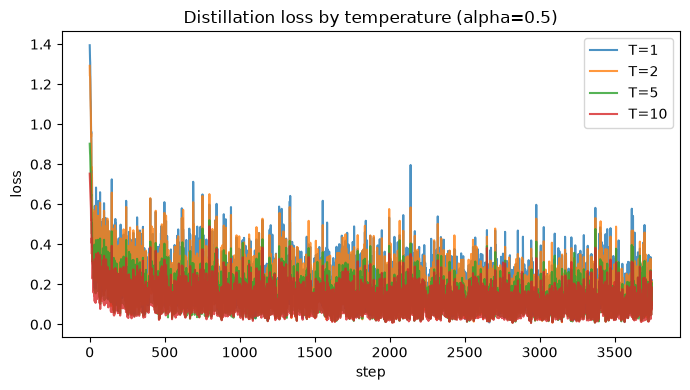

Sample training log (T = 2 ):
epoch=0 step=0 loss=1.2917 ce=1.4027 kld=1.1806
epoch=0 step=200 loss=0.1997 ce=0.2378 kld=0.1615
epoch=0 step=400 loss=0.3556 ce=0.4964 kld=0.2148
epoch=0 step=600 loss=0.1221 ce=0.1322 kld=0.1120
epoch=0 step=800 loss=0.1412 ce=0.1642 kld=0.1183
epoch=0 step=1000 loss=0.0823 ce=0.0783 kld=0.0863
epoch=0 step=1200 loss=0.3160 ce=0.3998 kld=0.2321
epoch=0 step=1400 loss=0.1220 ce=0.1266 kld=0.1175
epoch=0 step=1600 loss=0.2341 ce=0.2557 kld=0.2125
epoch=0 step=1800 loss=0.0681 ce=0.0642 kld=0.0719


In [11]:
plt.figure(figsize=(7, 4))
for T, hist in temp_loss_histories.items():
    plt.plot(hist, label=f'T={T}', alpha=0.8)
plt.xlabel('step')
plt.ylabel('loss')
plt.title('Distillation loss by temperature (alpha=0.5)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS, 'loss_trend_temperature_sweep.png'), dpi=150)
plt.show()

print('Sample training log (T =', best_T, '):')
print('\n'.join(temp_log_lines[best_T][:10]))

### Loss-weighting sweep (alpha = 0.25, 0.5, 0.75) at the best temperature

Three fresh students trained at `T = best_T`, varying only `alpha`.

In [12]:
alpha_sweep_results = {}
alpha_models = {}
alpha_loss_histories = {}
alpha_log_lines = {}

for alpha in [0.25, 0.5, 0.75]:
    print()
    print(f'=== Alpha sweep: T={best_T} (best), alpha={alpha} ===')
    model, log_lines, loss_history = train_student(T=best_T, alpha=alpha, seed=SEED, epochs=1, batch_size=32)
    acc, _, _ = evaluate_classifier(model, student_tokenizer, test_ds)
    print(f'alpha={alpha} -> test accuracy={acc:.4f}')
    alpha_sweep_results[alpha] = acc
    alpha_models[alpha] = model.cpu()
    torch.cuda.empty_cache()
    alpha_loss_histories[alpha] = loss_history
    alpha_log_lines[alpha] = log_lines

best_alpha = max(alpha_sweep_results, key=alpha_sweep_results.get)
print()
print('Alpha sweep results:', alpha_sweep_results)
print('Best alpha:', best_alpha)

INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/revision/main "HTTP/1.1 307 Temporary Redirect"



=== Alpha sweep: T=2 (best), alpha=0.25 ===


INFO:httpx2:HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/revision/main "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch=0 step=0 loss=1.2361 ce=1.4027 kld=1.1806


... (64 outputs left out)

epoch=0 step=3400 loss=0.2582 ce=0.2531 kld=0.2734


epoch=0 step=3600 loss=0.0833 ce=0.0912 kld=0.0597


alpha=0.75 -> test accuracy=0.9412



Alpha sweep results: {0.25: np.float64(0.9410526315789474), 0.5: np.float64(0.9415789473684211), 0.75: np.float64(0.9411842105263157)}
Best alpha: 0.5


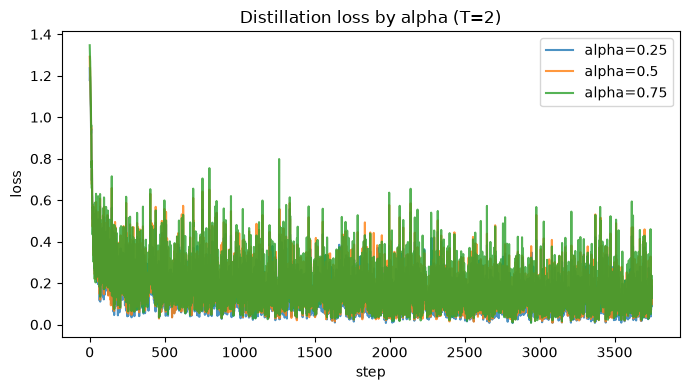

In [13]:
plt.figure(figsize=(7, 4))
for a, hist in alpha_loss_histories.items():
    plt.plot(hist, label=f'alpha={a}', alpha=0.8)
plt.xlabel('step')
plt.ylabel('loss')
plt.title(f'Distillation loss by alpha (T={best_T})')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ARTIFACTS, 'loss_trend_alpha_sweep.png'), dpi=150)
plt.show()

In [14]:
candidates = {('T', T): acc for T, acc in temp_sweep_results.items()}
candidates.update({('alpha', a): acc for a, acc in alpha_sweep_results.items()})
best_key = max(candidates, key=candidates.get)
print('Best overall config:', best_key, 'acc=', candidates[best_key])

if best_key[0] == 'T':
    best_student = temp_models[best_key[1]]
    best_T_final, best_alpha_final = best_key[1], ALPHA_FIXED
else:
    best_student = alpha_models[best_key[1]]
    best_T_final, best_alpha_final = best_T, best_key[1]

best_student = best_student.to(device)
print(f'Best distilled student: T={best_T_final}, alpha={best_alpha_final}')

BEST_STUDENT_DIR = os.path.join(ARTIFACTS, 'best_distilled_student')
best_student.save_pretrained(BEST_STUDENT_DIR)
student_tokenizer.save_pretrained(BEST_STUDENT_DIR)

Best overall config: ('T', 2) acc= 0.9415789473684211


Best distilled student: T=2, alpha=0.5


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('artifacts\\best_distilled_student\\tokenizer_config.json',
 'artifacts\\best_distilled_student\\tokenizer.json')

**Table HW11.2 — the separate distillation comparison on AG News** (test set, 7,600 examples; latency = median of 3 isolated runs, one model per process).

| Configuration | Accuracy | p50 / p95 latency (ms) | Peak memory (GB) | Size on disk (MB) |
|---|---|---|---|---|
| Teacher (BERT-base) | 0.9443 | 9.6 / 11.1 | 0.422 | 418.6 |
| Best distilled student (DistilBERT, T=2, alpha=0.5) | 0.9416 | 4.6 / 5.5 | 0.263 | 256.1 |

(In the code cell above, teacher and student both show peak memory 1.080 GB. That is a measurement artifact: both models were resident on the GPU in the same process. The values in this table are from the isolated re-measurement.)

**Sweeps** (every student trained for **1 epoch**, 3,750 steps at batch 32, because of the time limit on a 6 GB laptop GPU; one seed, SEED = 2708). Temperature sweep at alpha = 0.5: T=1: 0.9392, **T=2: 0.9416**, T=5: 0.9409, T=10: 0.9387. Loss-weighting sweep at T=2: alpha=0.25: 0.9411, **alpha=0.5: 0.9416**, alpha=0.75: 0.9412. All of these lie within about 0.3 points (roughly 20 of 7,600 test examples) of each other from a single seed, so the "best" settings are not statistically distinguishable from the others. The distilled student is 0.28 points below the teacher, about 2.1x faster at p50, 39% smaller on disk and uses 38% less peak memory.

In [15]:
teacher_acc, teacher_preds, test_labels = evaluate_classifier(teacher_model, teacher_tokenizer, test_ds)
student_acc, student_preds, _ = evaluate_classifier(best_student, student_tokenizer, test_ds)

teacher_p50, teacher_p95, teacher_mem = measure_latency_memory(teacher_model, teacher_tokenizer.vocab_size, seq_len=MAX_LEN)
student_p50, student_p95, student_mem = measure_latency_memory(best_student, student_tokenizer.vocab_size, seq_len=MAX_LEN)

TEACHER_SIZE_MB = get_dir_size_mb(TEACHER_DIR)
STUDENT_SIZE_MB = get_dir_size_mb(BEST_STUDENT_DIR)

table_hw_2 = pd.DataFrame({
    'Teacher (BERT-base)': [teacher_acc, teacher_p50, teacher_p95, teacher_mem, TEACHER_SIZE_MB],
    'Best distilled student': [student_acc, student_p50, student_p95, student_mem, STUDENT_SIZE_MB],
}, index=['Accuracy', 'p50 latency (ms)', 'p95 latency (ms)', 'Peak memory (GB)', 'Size on disk (MB)']).T
table_hw_2

,Accuracy,p50 latency (ms),p95 latency (ms),Peak memory (GB),Size on disk (MB)
Teacher (BERT-base),0.944342,10.0540,11.9299,1.080287,418.578126
Best distilled student,0.941579,5.1775,5.7889,1.080287,256.110729


In [16]:
def per_class_accuracy(preds, labels, id2label):
    accs = {}
    for cls_id, name in id2label.items():
        mask = labels == cls_id
        accs[name] = (preds[mask] == labels[mask]).mean() if mask.sum() > 0 else float('nan')
    return accs

teacher_per_class = per_class_accuracy(teacher_preds, test_labels, id2label)
student_per_class = per_class_accuracy(student_preds, test_labels, id2label)

per_class_df = pd.DataFrame({'Teacher': teacher_per_class, 'Student': student_per_class})
per_class_df['Drop'] = per_class_df['Teacher'] - per_class_df['Student']
per_class_df = per_class_df.sort_values('Drop', ascending=False)
print(per_class_df)

worst_class = per_class_df.index[0]
print()
print(f'Most-degraded class: {worst_class}')

teacher_correct_student_wrong = np.where((teacher_preds == test_labels) & (student_preds != test_labels))[0]
sample_idx = teacher_correct_student_wrong[:5]
test_texts = test_ds['text']
print()
print(f'{len(teacher_correct_student_wrong)} examples where teacher is right and student is wrong. Showing 5:')
print()
for i in sample_idx:
    i = int(i)
    print(f'[true={id2label[int(test_labels[i])]}, student_pred={id2label[int(student_preds[i])]}]')
    print(test_texts[i][:300])
    print('---')

           Teacher   Student      Drop
BUSINESS  0.913684  0.890526  0.023158
SPORTS    0.988421  0.987895  0.000526
SCI/TECH  0.926316  0.931053 -0.004737
WORLD     0.948947  0.956842 -0.007895

Most-degraded class: BUSINESS

165 examples where teacher is right and student is wrong. Showing 5:

[true=SPORTS, student_pred=WORLD]
Shoppach doesn't appear ready to hit the next level With the weeks dwindling until Jason Varitek enters free agency, the Red Sox continue to carefully monitor Kelly Shoppach , their catcher of the future, in his climb toward the majors. The Sox like most of what they have seen at Triple A Pawtucket 
---
[true=SCI/TECH, student_pred=BUSINESS]
Dell Exits Low-End China Consumer PC Market  HONG KONG (Reuters) - Dell Inc. &lt;DELL.O&gt;, the world's  largest PC maker, said on Monday it has left the low-end  consumer PC market in China and cut its overall growth target  for the country this year due to stiff competition in the  segment.
---
[true=SCI/TECH, student_pr

**Where the compression hurts.** BUSINESS degrades most (teacher 0.9137 to student 0.8905, a drop of 2.3 points); SPORTS is essentially unchanged and SCI/TECH and WORLD are slightly *better* for the student.

**What the five examples have in common.** All five sit on the boundary between two categories or lack a clear topical cue early in the text: the Dell/China item is a tech company but the story is about market share and growth targets (SCI/TECH vs BUSINESS), the Yahoo item is a business story told in web-hosting vocabulary (BUSINESS vs SCI/TECH), the missile-defense item is a politics story with a technology keyword (WORLD vs SCI/TECH), and the vision-problems and Red Sox items open with prose that has no obvious topic words. The student appears to lean on surface keywords more than the teacher does. Caveat: these are the first five of 165 teacher-right/student-wrong cases by index, not a random sample, so this is an impression from five examples, not a measured pattern; the BUSINESS-vs-SCI/TECH confusions are consistent with BUSINESS being the most degraded class.

In [17]:
print('GPTQ: {:.0f} MB -> {:.0f} MB on disk, p50 {:.2f} ms -> {:.2f} ms'.format(base_size_mb, q_size_mb, base_p50, q_p50))
print('Distillation: {:.0f} MB -> {:.0f} MB on disk, p50 {:.2f} ms -> {:.2f} ms, accuracy {:.4f} -> {:.4f}'.format(
    TEACHER_SIZE_MB, STUDENT_SIZE_MB, teacher_p50, student_p50, teacher_acc, student_acc))

GPTQ: 241 MB -> 121 MB on disk, p50 11.53 ms -> 75.28 ms
Distillation: 419 MB -> 256 MB on disk, p50 10.05 ms -> 5.18 ms, accuracy 0.9443 -> 0.9416


## Quantization vs. distillation (4-6 sentences)

Quantization (GPTQ) keeps the architecture and stores each weight in 4 bits after training, using only a small calibration set, whereas distillation trains a new, smaller network (6-layer DistilBERT) to imitate the teacher, which needs a full training run. In our measurements GPTQ halved the on-disk size (240.8 to 121.1 MB) and cut peak memory by about a third (0.262 to 0.175 GB), but with the pure-PyTorch kernel available here its latency got about 3x worse (p50 13.2 to 39.9 ms). Distillation cut size by 39% (418.6 to 256.1 MB), peak memory by 38% (0.422 to 0.263 GB) and p50 latency by about half (9.6 to 4.6 ms), because it removes layers and therefore actually does less computation, while quantization only saves bytes and saves time only when fast low-bit kernels exist. For a latency-bound deployment I would try distillation first (or GPTQ only on a platform with optimized kernels such as Marlin on Linux), and for a memory-bound deployment I would try GPTQ first, since it shrinks the weights with no retraining and works on any architecture. These are single-seed, 1-epoch, single-GPU numbers, so the direction of the differences is more trustworthy than the exact figures.

## Deliverables checklist (Section 0.3)

- [x] This executed notebook, with outputs intact
- [x] `RUN_LOG.txt` — console output from the run(s) that produced the numbers above
- [x] `METRICS.md` — Table HW11.1 and Table HW11.2
- [x] `AI_USE.md` — per Section 0.5
- [x] Model checkpoints (`artifacts/gpt2-gptq-4bit`, `artifacts/best_distilled_student`) or a link, plus the commands used to produce them
- [x] Commit incrementally, then tag `hw12`